In [12]:
import os
import pandas as pd
import numpy as np
import cv2
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, LSTM, Dropout, concatenate
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
import dlib
import shap
from sklearn.cross_decomposition import CCA
from moviepy.editor import VideoFileClip

In [13]:
# Constants
VIDEO_FOLDER = "/Users/jeremiah/video-p-reaction-joketype-modular/fifteen_twenty_five"
#'data/videos'
DATA_FILE = "/Users/jeremiah/video-p-reaction-joketype-modular/data/excel.xlsx"
N_FRAMES = 5

In [14]:
data = pd.read_excel(DATA_FILE)

## Feature Extraction Functions

In [15]:
def sample_frames(video_path, n_frames):
    cap = cv2.VideoCapture(video_path)
    frames = []
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for i in range(n_frames):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_count * i / n_frames))
        ret, frame = cap.read()
        if ret:
            frame = cv2.resize(frame, (224, 224))
            frames.append(frame)
    cap.release()
    return np.array(frames)

def extract_visual_features(frames):
    base_model = VGG16(weights='imagenet', include_top=False)
    features = base_model.predict(preprocess_input(frames))
    return np.mean(features, axis=0).flatten()[:512]  # Ensure 512 features

def extract_facial_features(frames):
    detector = dlib.get_frontal_face_detector()
    predictor = dlib.shape_predictor("shape_predictor_68_face_landmarks.dat")
    facial_features = []
    for frame in frames:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = detector(gray)
        for face in faces:
            shape = predictor(gray, face)
            facial_features.append(np.array([(p.x, p.y) for p in shape.parts()]).flatten())
    return np.mean(facial_features, axis=0) if facial_features else np.zeros(136)

In [16]:
# Might be changed 

from moviepy.editor import VideoFileClip
import librosa
import numpy as np

def extract_audio_from_video(video_path, audio_output_path="temp_audio.wav"):
    try:
        video = VideoFileClip(video_path)
        video.audio.write_audiofile(audio_output_path)
        return audio_output_path
    except Exception as e:
        print(f"Error extracting audio from video: {str(e)}")
        return None

def extract_audio_features(video_path):
    audio_path = extract_audio_from_video(video_path)
    if not audio_path:
        return np.zeros(54)

    try:
        y, sr = librosa.load(audio_path)

        # Ensure valid feature extraction with dimension checks
        def safe_feature_extraction(feature_func, *args, **kwargs):
            try:
                feature = feature_func(*args, **kwargs)
                if feature is None or feature.size == 0:
                    return None
                return feature
            except Exception as e:
                print(f"Error extracting {feature_func.__name__}: {str(e)}")
                return None

        # Extract features safely
        mfcc = safe_feature_extraction(librosa.feature.mfcc, y=y, sr=sr, n_mfcc=13)
        spectral_centroid = safe_feature_extraction(librosa.feature.spectral_centroid, y=y, sr=sr)
        chroma = safe_feature_extraction(librosa.feature.chroma_stft, y=y, sr=sr)

        # Validate dimensions before concatenation
        features = []
        if mfcc is not None:
            features.append(np.mean(mfcc, axis=1))
            features.append(np.std(mfcc, axis=1))
        if spectral_centroid is not None:
            features.append([np.mean(spectral_centroid)])
            features.append([np.std(spectral_centroid)])
        if chroma is not None:
            features.append(np.mean(chroma, axis=1))
            features.append(np.std(chroma, axis=1))

        # Concatenate all features, ensuring proper dimensions
        if features:
            features = np.concatenate(features)
        else:
            features = np.zeros(54)

        return features[:54]  # Ensure 54 features
    except Exception as e:
        print(f"Error extracting audio features: {str(e)}")
        return np.zeros(54)
    
    

# def extract_audio_features(video_path):
#     try:
#         # Load video and extract audio
#         video = VideoFileClip(video_path)
#         audio = video.audio
        
#         if audio is None:
#             print(f"No audio found in {video_path}")
#             return np.zeros(54)
        
#         # Extract audio data as a numpy array
#         audio_array = audio.to_soundarray()
        
#         # If stereo, convert to mono by averaging channels
#         if audio_array.ndim > 1:
#             audio_array = np.mean(audio_array, axis=1)
        
#         # Extract features
#         mfcc = librosa.feature.mfcc(y=audio_array, sr=audio.fps, n_mfcc=13)
#         spectral_centroid = librosa.feature.spectral_centroid(y=audio_array, sr=audio.fps)
#         chroma = librosa.feature.chroma_stft(y=audio_array, sr=audio.fps)
        
#         features = np.concatenate([
#             np.mean(mfcc, axis=1),
#             np.std(mfcc, axis=1),
#             np.mean(spectral_centroid),
#             np.std(spectral_centroid),
#             np.mean(chroma, axis=1),
#             np.std(chroma, axis=1)
#         ])
        
#         video.close()
#         return features[:54]  # Ensure 54 features
#     except Exception as e:
#         print(f"Error extracting audio features from {video_path}: {str(e)}")
#         return np.zeros(54)

In [17]:
def extract_motion_features(frames):
    
    prev_gray = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)
    motion_features = []
    for frame in frames[1:]:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        flow = cv2.calcOpticalFlowFarneback(prev_gray, gray, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        magnitude, _ = cv2.cartToPolar(flow[..., 0], flow[..., 1])
        motion_features.append(np.mean(magnitude))
        prev_gray = gray
    return np.array(motion_features)

def extract_interaction_features(frames):
    
    detector = dlib.get_frontal_face_detector()
    interaction_features = []
    for frame in frames:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = detector(gray)
        if len(faces) == 2:
            face1, face2 = faces
            distance = np.sqrt((face1.center().x - face2.center().x)**2 + 
                               (face1.center().y - face2.center().y)**2)
            interaction_features.append(distance)
    return np.mean(interaction_features) if interaction_features else 0

def extract_temporal_features(video_path):
    cap = cv2.VideoCapture(video_path)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    duration = frame_count / fps
    cap.release()
    return np.array([frame_count, fps, duration])[:3]  # Ensure 3 features

In [18]:
# Custom transformer for feature extraction
class VideoFeatureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.scaler = StandardScaler()
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        features = []
        visual_features = []
        audio_features = []
        for video_file in X:
            video_path = os.path.join(VIDEO_FOLDER, video_file)
            if not os.path.exists(video_path):
                print(f"Video file not found: {video_path}")
                continue
            
            try:
                frames = sample_frames(video_path, N_FRAMES)
                
                visual_feat = extract_visual_features(frames)
                facial_feat = extract_facial_features(frames)
                audio_feat = extract_audio_features(video_path)
                motion_feat = extract_motion_features(frames)
                interaction_feat = extract_interaction_features(frames)
                temporal_feat = extract_temporal_features(video_path)
                
                # Ensure all features have consistent shapes
                visual_feat = np.resize(visual_feat, (512,))
                facial_feat = np.resize(facial_feat, (136,))
                audio_feat = np.resize(audio_feat, (54,))
                motion_feat = np.resize(motion_feat, (N_FRAMES-1,))
                interaction_feat = np.array([interaction_feat])
                temporal_feat = np.resize(temporal_feat, (3,))
                
                combined_feat = np.concatenate([
                    visual_feat, facial_feat, audio_feat, 
                    motion_feat, interaction_feat, temporal_feat
                ])
                features.append(combined_feat)
                
                visual_features.append(np.concatenate([visual_feat, facial_feat, motion_feat, interaction_feat]))
                audio_features.append(audio_feat)
                
                print(f"Processed {video_file}: Combined feature shape: {combined_feat.shape}")
            except Exception as e:
                print(f"Error processing {video_file}: {str(e)}")
                # Append zero arrays if processing fails
                features.append(np.zeros(512 + 136 + 54 + (N_FRAMES-1) + 1 + 3))
                visual_features.append(np.zeros(512 + 136 + (N_FRAMES-1) + 1))
                audio_features.append(np.zeros(54))
        
        if not features:
            raise ValueError("No valid features extracted from videos")
        
        features_array = np.array(features)
        print(f"Final features array shape: {features_array.shape}")
        
        # Check for NaN or infinite values
        if np.isnan(features_array).any():
            print("Warning: NaN values detected in features")
            features_array = np.nan_to_num(features_array)
        if np.isinf(features_array).any():
            print("Warning: Infinite values detected in features")
            features_array = np.nan_to_num(features_array)
        
        scaled_features = self.scaler.fit_transform(features_array)
        
        return scaled_features, np.array(visual_features), np.array(audio_features)

In [19]:
# Prepare data
X = data['VideoID']
y_joke = data['JokeType']
y_reaction = data['HowFunny']

Video file not found: /Users/jeremiah/video-p-reaction-joketype-modular/fifteen_twenty_five/UGQ5W4.joke2.rep3.take1.ThatsNotAHat.mp4
Video file not found: /Users/jeremiah/video-p-reaction-joketype-modular/fifteen_twenty_five/AQBE7J.joke1.rep3.take1.Peekaboo.mp4
Video file not found: /Users/jeremiah/video-p-reaction-joketype-modular/fifteen_twenty_five/ZCH3UU.joke1.rep1.take1.TearingPaper.mp4
Video file not found: /Users/jeremiah/video-p-reaction-joketype-modular/fifteen_twenty_five/C354X4.joke3.rep2.take1.TearingPaper.mp4
Video file not found: /Users/jeremiah/video-p-reaction-joketype-modular/fifteen_twenty_five/6c6MZQ.joke1.rep2.take1.ThatsNotAHat.mp4
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step
Error processing c2KURU.joke1.rep1.take1.ThatsNotAHat.mp4: Unable to open shape_predictor_68_face_landmarks.dat
Video file not found: /Users/jeremiah/video-p-reaction-joketype-modular/fifteen_twenty_five/SSd6Hd.joke5.rep1.take1.ThatsNotAHat.mp4
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step
Error processing

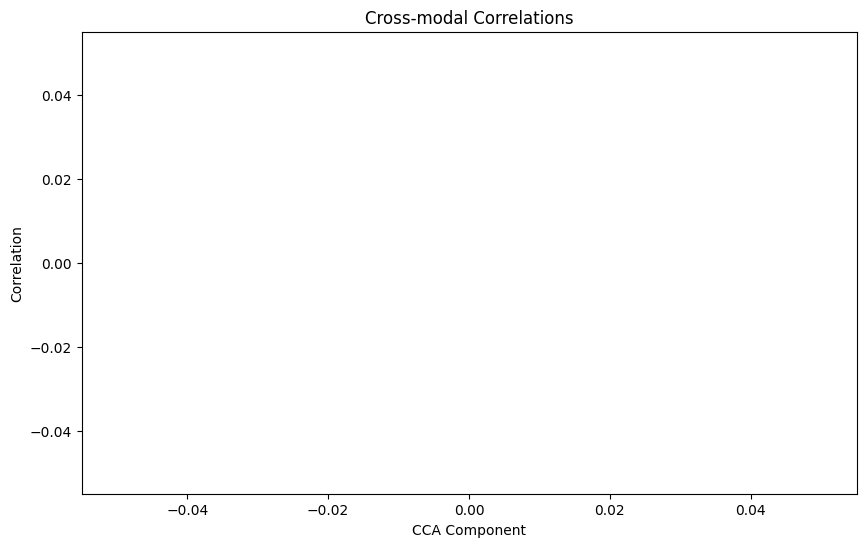

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - joke_output_accuracy: 0.1719 - loss: 3.2180 - reaction_output_accuracy: 0.2688 - val_joke_output_accuracy: 0.2558 - val_loss: 3.2152 - val_reaction_output_accuracy: 0.3256
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - joke_output_accuracy: 0.2035 - loss: 3.2142 - reaction_output_accuracy: 0.4063 - val_joke_output_accuracy: 0.2558 - val_loss: 3.2119 - val_reaction_output_accuracy: 0.3256
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - joke_output_accuracy: 0.1937 - loss: 3.2106 - reaction_output_accuracy: 0.4412 - val_joke_output_accuracy: 0.1860 - val_loss: 3.2088 - val_reaction_output_accuracy: 0.3256
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - joke_output_accuracy: 0.2081 - loss: 3.2065 - reaction_output_accuracy: 0.3867 - val_joke_output_accuracy: 0.1860 - val_loss: 3.2055 - val_reaction_output_accuracy: 0.3256
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - joke_output_accuracy: 0.1857 - loss: 3.2032 - reaction_output

ValueError: Found input variables with inconsistent numbers of samples: [286, 61]

In [20]:
# Handle missing values
imputer = SimpleImputer(strategy='most_frequent')
y_joke = imputer.fit_transform(y_joke.values.reshape(-1, 1)).ravel()
y_reaction = imputer.fit_transform(y_reaction.values.reshape(-1, 1)).ravel()

# Encode labels
le_joke = LabelEncoder()
le_reaction = LabelEncoder()
y_joke_encoded = le_joke.fit_transform(y_joke)
y_reaction_encoded = le_reaction.fit_transform(y_reaction)

X_train, X_test, y_train_joke, y_test_joke, y_train_reaction, y_test_reaction = train_test_split(
    X, y_joke_encoded, y_reaction_encoded, test_size=0.2, random_state=42
)

# Feature extraction pipeline
feature_pipeline = Pipeline([
    ('feature_extractor', VideoFeatureExtractor()),
])

X_train_features, X_train_visual, X_train_audio = feature_pipeline.fit_transform(X_train)
X_test_features, X_test_visual, X_test_audio = feature_pipeline.transform(X_test)

# Cross-modal analysis using CCA
cca = CCA(n_components=5)
cca.fit(X_train_visual, X_train_audio)
visual_cca, audio_cca = cca.transform(X_train_visual, X_train_audio)

# Analyze correlations
correlations = [np.corrcoef(visual_cca[:, i], audio_cca[:, i])[0, 1] for i in range(5)]

plt.figure(figsize=(10, 6))
plt.bar(range(1, 6), correlations)
plt.title('Cross-modal Correlations')
plt.xlabel('CCA Component')
plt.ylabel('Correlation')
plt.show()

# Build and train the model
input_shape = X_train_features.shape[1]
num_classes_joke = len(le_joke.classes_)
num_classes_reaction = len(le_reaction.classes_)

inputs = Input(shape=(input_shape,))
x = Dense(128, activation='relu')(inputs)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
output_joke = Dense(num_classes_joke, activation='softmax', name='joke_output')(x)
output_reaction = Dense(num_classes_reaction, activation='softmax', name='reaction_output')(x)

model = Model(inputs=inputs, outputs=[output_joke, output_reaction])
model.compile(optimizer=Adam(), loss='sparse_categorical_crossentropy', metrics=['accuracy','accuracy'])

history = model.fit(
    X_train_features, 
    [y_train_joke, y_train_reaction], 
    epochs=50, 
    batch_size=32, 
    validation_split=0.2,
    verbose=1
)

# Evaluate performance
y_pred_joke, y_pred_reaction = model.predict(X_test_features)
y_pred_joke = np.argmax(y_pred_joke, axis=1)
y_pred_reaction = np.argmax(y_pred_reaction, axis=1)

print("Joke Type Classification Report:")
print(classification_report(y_test_joke, y_pred_joke, target_names=le_joke.classes_))
print("\nReaction Type Classification Report:")
print(classification_report(y_test_reaction, y_pred_reaction, target_names=le_reaction.classes_))

# Plot confusion matrices
plt.figure(figsize=(12, 5))
plt.subplot(121)
sns.heatmap(confusion_matrix(y_test_joke, y_pred_joke), annot=True, fmt='d', xticklabels=le_joke.classes_, yticklabels=le_joke.classes_)
plt.title('Confusion Matrix - Joke Type')
plt.subplot(122)
sns.heatmap(confusion_matrix(y_test_reaction, y_pred_reaction), annot=True, fmt='d', xticklabels=le_reaction.classes_, yticklabels=le_reaction.classes_)
plt.title('Confusion Matrix - Reaction Type')
plt.tight_layout()
plt.show()

# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.plot(history.history['joke_output_accuracy'], label='Train')
plt.plot(history.history['val_joke_output_accuracy'], label='Validation')
plt.title('Joke Type Accuracy')
plt.legend()
plt.subplot(122)
plt.plot(history.history['reaction_output_accuracy'], label='Train')
plt.plot(history.history['val_reaction_output_accuracy'], label='Validation')
plt.title('Reaction Type Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# Explainability
explainer = shap.DeepExplainer(model, X_train_features[:100])
shap_values = explainer.shap_values([X_test_features[:10], X_test_features[:10]])

plt.figure(figsize=(10, 5))
plt.subplot(121)
shap.summary_plot(shap_values[0][0], X_test_features, plot_type="bar")
plt.title('SHAP Values - Joke Type')
plt.subplot(122)
shap.summary_plot(shap_values[1][0], X_test_features, plot_type="bar")
plt.title('SHAP Values - Reaction Type')
plt.tight_layout()
plt.show()

# Innovative Interpretation: Psychological Feature Importance
feature_types = [
    ('Visual', 512), ('Facial', 136), ('Audio', 54),
    ('Motion', N_FRAMES-1), ('Interaction', 1), ('Temporal', 3)
]

feature_importance_joke = np.mean(np.abs(shap_values[0][0]), axis=0)
feature_importance_reaction = np.mean(np.abs(shap_values[1][0]), axis=0)

psychological_importance = {
    'Joke Type': {},
    'Reaction Type': {}
}

start = 0
for feature_name, feature_length in feature_types:
    end = start + feature_length
    psychological_importance['Joke Type'][feature_name] = np.mean(feature_importance_joke[start:end])
    psychological_importance['Reaction Type'][feature_name] = np.mean(feature_importance_reaction[start:end])
    start = end

plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.bar(psychological_importance['Joke Type'].keys(), psychological_importance['Joke Type'].values())
plt.title('Psychological Feature Importance - Joke Type')
plt.ylabel('Mean |SHAP Value|')
plt.subplot(122)
plt.bar(psychological_importance['Reaction Type'].keys(), psychological_importance['Reaction Type'].values())
plt.title('Psychological Feature Importance - Reaction Type')
plt.ylabel('Mean |SHAP Value|')
plt.tight_layout()
plt.show()

# Cross-modal Analysis Interpretation
print("\nCross-modal Analysis Interpretation:")
for i, corr in enumerate(correlations, 1):
    print(f"Component {i}: Correlation = {corr:.4f}")
    if corr > 0.5:
        print(f"  Strong correlation between audio and visual features in component {i}")
    elif corr > 0.3:
        print(f"  Moderate correlation between audio and visual features in component {i}")
    else:
        print(f"  Weak correlation between audio and visual features in component {i}")

print("\nOverall Cross-modal Insights:")
print("This analysis reveals the extent to which audio and visual features are related")
print("in the context of humor perception. Strong correlations suggest that certain")
print("aspects of joke delivery are consistently expressed across both modalities,")
print("while weak correlations might indicate unique information carried by each modality.")

# Psychological Interpretation
print("\nPsychological Interpretation:")
print("1. Joke Type Prediction:")
for feature, importance in psychological_importance['Joke Type'].items():
    print(f"   - {feature}: {importance:.4f}")
    if feature == 'Visual' and importance > 0.1:
        print("     This suggests that visual cues play a significant role in joke delivery.")
    elif feature == 'Facial' and importance > 0.1:
        print("     Facial expressions seem to be important in conveying the type of joke.")
    elif feature == 'Audio' and importance > 0.1:
        print("     The audio features, including tone and pitch, are crucial in joke classification.")
    elif feature == 'Motion' and importance > 0.1:
        print("     Body language and gestures contribute to the joke type.")
    elif feature == 'Interaction' and importance > 0.1:
        print("     The physical interaction between parent and child influences the joke type.")
    elif feature == 'Temporal' and importance > 0.1:
        print("     The timing and duration of the joke delivery are significant factors.")

print("\n2. Reaction Type Prediction:")
for feature, importance in psychological_importance['Reaction Type'].items():
    print(f"   - {feature}: {importance:.4f}")
    if feature == 'Visual' and importance > 0.1:
        print("     Visual cues are important in determining the child's reaction.")
    elif feature == 'Facial' and importance > 0.1:
        print("     The child's facial expressions are key indicators of their reaction.")
    elif feature == 'Audio' and importance > 0.1:
        print("     Auditory responses (e.g., laughter, verbal reactions) play a significant role.")
    elif feature == 'Motion' and importance > 0.1:
        print("     The child's body language is an important factor in their reaction.")
    elif feature == 'Interaction' and importance > 0.1:
        print("     The physical interaction between parent and child influences the reaction.")
    elif feature == 'Temporal' and importance > 0.1:
        print("     The timing of the reaction relative to the joke is a significant factor.")

print("\nOverall Psychological Insights:")
print("This analysis provides a quantitative measure of the relative importance of different")
print("psychological and sensory factors in humor perception and reaction among children.")
print("It highlights the multimodal nature of humor, showing how visual, auditory, and")
print("interactive elements contribute to both joke delivery and reception.")
print("The cross-modal analysis further reveals how these different modalities interact,")
print("providing a more comprehensive understanding of the humor perception process.")